# Large-angle CBED of Silicon

This notebook simulates large-angle convergent beam electron diffraction (LACBED) with pyEMAPS,
step by step. It follows the *si_lacbed.py* sample, one step per cell.

You'll:

1. simulate LACBED images, one per diffracted beam, and find out which beam each one shows;
2. explain the bright line across each image with Bragg's law;
3. see how the images change with the sample thickness and the zone axis;
4. save the images to a file.

**LACBED in brief.** In CBED, the beam converges onto the sample in a cone, and each diffracted
beam is a disk; each point in a disk is a different incident direction. The larger the
convergence angle, the more incident directions a pattern covers, but once it exceeds the Bragg
angle, neighboring disks overlap. LACBED gets around this: the beam is focused above or below
the sample, so that an aperture can select a single diffracted beam. Each LACBED image then
shows one beam's intensity over a range of incident directions several times the Bragg angle.

pyEMAPS simulates LACBED with the Bloch wave method of the
[dynamic diffraction notebook](si_bloch.ipynb). It calculates every beam at every incident
direction, as for CBED, and puts each beam in an image of its own.

**Requirements.** pyEMAPS on Windows, with Python 3.12 to 3.15, and Jupyter in the same
environment:

```
pip install pyemaps jupyter
```

## Step 1: Import pyEMAPS and load a crystal

`TY_LACBED` selects LACBED images in `generateBloch`.

In [1]:
import math
from importlib.metadata import version

import matplotlib.pyplot as plt
import numpy as np

from pyemaps import EMC, TY_LACBED, BImgList, Crystal, showBloch

print('pyEMAPS', version('pyemaps'))

silicon = Crystal.from_builtin('Silicon')

pyEMAPS 2.2.0


## Step 2: Simulate LACBED images

The *si_lacbed.py* sample calls `generateBloch` with `nType=TY_LACBED`, a disk size of 0.5 1/Å,
10 sampling points along the disk radius, and one sample thickness, 1000 Å. It returns one image
per diffracted beam.

In [2]:
images = silicon.generateBloch(disk_size=0.5, sampling=10, nType=TY_LACBED,
                               sample_thickness=(1000, 1000, 100))

print(len(images.blochList), 'images')
emc, image = images[0]
print(emc)

21 images
Electron microscope controls
  Mode                      CBED, disk size 0.5   (default Normal)
  Zone axis                 [0 0 1]
  Tilt (x, y)               (0, 0) degrees
  Shift (x, y)              (0, 0)
  Camera length             200 mm   (default 1000 mm)
  High voltage              200 kV
  Horizontal axis           (0 2 0)
  Detector pixel size       25 µm
  Detector size             512 pixels
  Objective aperture        1
Simulation controls
  Excitation error range    0.3 to 1   (default 0.3 to 2)
  Max. reciprocal vector    1 1/Å   (default 3.5 1/Å)
  Beta perturbation cutoff  0.1
  Intensity cutoff, scale   0, 5
  Max. g-list index         6
  Max. zone axis index      5
  Diagonalization cutoff    10
  Sampling points           10   (default 8)
  Sample thickness          1000 Å   (default 200 Å)


The disk size is the radius of the range of incident directions, in reciprocal space. At 200
kV it's a convergence semi-angle of $\alpha = \lambda \times$ 0.5 1/Å. Compare it with the
Bragg angle of Silicon's (2 2 0), $\theta_B = \lambda |\mathbf g| / 2$:

In [3]:
h, m0, e, c = 6.62607015e-34, 9.1093837015e-31, 1.602176634e-19, 299792458.0   # SI units
E = emc.vt * 1e3                                                              # V
lam = h / math.sqrt(2 * m0 * e * E * (1 + e * E / (2 * m0 * c**2))) * 1e10       # Å

a = silicon.cell.a
g220 = math.sqrt(8) / a
print(f'Convergence semi-angle: {lam * 0.5 * 1e3:.1f} mrad')
print(f'Bragg angle of (2 2 0): {lam * g220 / 2 * 1e3:.1f} mrad')

Convergence semi-angle: 12.5 mrad
Bragg angle of (2 2 0): 6.5 mrad


The convergence is about twice the Bragg angle. In an ordinary CBED pattern these disks
would overlap; as separate LACBED images, they don't.

## Step 3: Which beam is which

Each image comes with the same controls, so they don't say which beam it shows. A dynamic
diffraction session does: `beginBloch` starts it, `getCalculatedBeams` lists the beams in the
order of the images, `getBlochImages` makes the images, and `endBloch` frees the memory.
`generateBloch` makes the same calls in one go. The calculated beams are the ones inside the
objective aperture, 1 1/Å by default.

In [4]:
npoints, _ = silicon.beginBloch(dbsize=0.5, sampling=10)
nbeams, beams = silicon.getCalculatedBeams()
lacbed = silicon.getBlochImages(sample_thickness=(1000, 1000, 100), nType=TY_LACBED)
silicon.endBloch()

same = all(np.array_equal(a1, a2) for (_, a1), (_, a2) in zip(images, lacbed.blochList))
print(f'{npoints} sampling points, {nbeams} beams; the same images as generateBloch: {same}')
print()
print('  beam        largest intensity')
for (emc, image), hkl in zip(lacbed.blochList, beams):
    print(f'  {str(tuple(int(i) for i in hkl)):12s} {image.max():.2g}')

317 sampling points, 21 beams; the same images as generateBloch: True

  beam        largest intensity
  (0, 0, 0)    0.85
  (0, -2, 0)   9.4e-12
  (-2, 0, 0)   1e-11
  (2, 0, 0)    5.2e-12
  (0, 2, 0)    1.3e-11
  (2, -2, 0)   0.8
  (-2, 2, 0)   0.8
  (-2, -2, 0)  0.8
  (2, 2, 0)    0.8
  (0, -4, 0)   0.51
  (-4, 0, 0)   0.51
  (4, 0, 0)    0.51
  (0, 4, 0)    0.51
  (2, -4, 0)   9e-13
  (4, -2, 0)   6.5e-13
  (-4, 2, 0)   5.4e-13
  (-2, 4, 0)   1.3e-12
  (-2, -4, 0)  7.6e-13
  (-4, -2, 0)  6.5e-13
  (4, 2, 0)    4.8e-13
  (2, 4, 0)    1.1e-12


Only nine images aren't dark: the direct beam, (0 0 0), and the four (2 2 0)-type and four
(4 0 0)-type reflections. The other twelve, the (2 0 0) and (4 2 0) types, are forbidden in the
diamond structure, as the [structure factors notebook](si_csf.ipynb) shows. In dynamic
diffraction, a forbidden reflection can still light up when electrons reach it through other
reflections, but no chain of the allowed reflections in this layer of the reciprocal lattice
adds up to one of these, so they stay dark: the $10^{-11}$ is rounding error.

## Step 4: Display the images

`showBloch` displays images from a `BImgList`. Here is the direct beam's image, the
**bright-field** LACBED image:

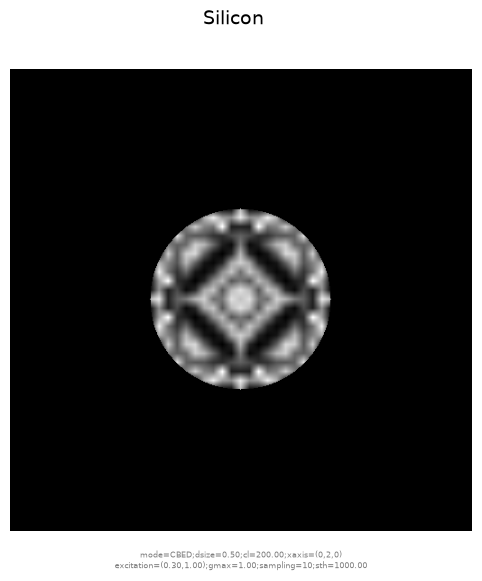

In [5]:
direct = BImgList('Silicon')
direct.add(*lacbed[0])
showBloch(direct)

The 512 × 512 pixel detector is much larger than the disk. The cell below zooms in on it,
with the eight reflections, each labelled with its beam:

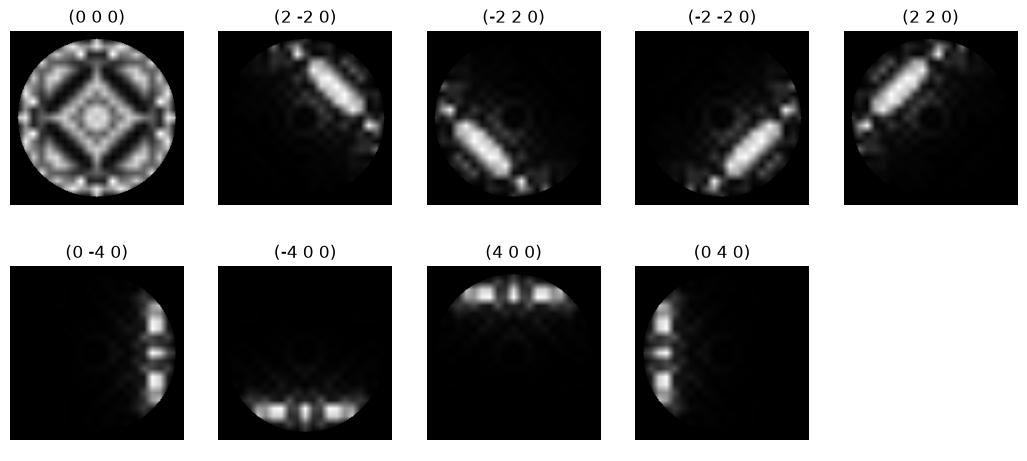

In [6]:
bright = [i for i, (emc, image) in enumerate(lacbed.blochList) if image.max() > 1e-3]

image0 = lacbed[0][1]
rows, cols = np.nonzero(image0)
center = np.array([cols.mean(), rows.mean()])      # the disk center, in pixels (x, y)
radius = math.sqrt(len(rows) / math.pi)


def zoom(ax):
    ax.set_xlim(center[0] - 1.1 * radius, center[0] + 1.1 * radius)
    ax.set_ylim(center[1] + 1.1 * radius, center[1] - 1.1 * radius)
    ax.axis('off')


def label(hkl):
    return '(' + ' '.join(str(int(i)) for i in hkl) + ')'


fig, axes = plt.subplots(2, 5, figsize=(13, 5.6))
for ax, i in zip(axes.flat, bright):
    ax.imshow(lacbed[i][1], cmap='gray')
    ax.set_title(label(beams[i]))
    zoom(ax)
axes.flat[-1].axis('off')
plt.show()

Each reflection's image has a bright band across it, on the side away from the reflection:
the (4 0 0) band near the top, the (-4 0 0) band near the bottom. In these images, (0 1 0)
points to the right, along the horizontal axis printed with the controls, and (1 0 0) points
down.

## Step 5: The Bragg lines

Why a band? A point in the disk is an incident direction, tilted from the zone axis by a
small vector $\mathbf t$ in reciprocal space. A reflection $\mathbf g$ in the zone is at its
Bragg condition when the incident and diffracted wave vectors have the same length,
$|\mathbf k + \mathbf g| = |\mathbf k|$, which works out to

$$\mathbf t \cdot \hat{\mathbf g} = -\frac{|\mathbf g|}{2}$$

That is a line across the disk, perpendicular to $\mathbf g$, at a distance $|\mathbf g|/2$
from the center on the side opposite $\mathbf g$. Along it, the reflection is strong. On the
detector, a vector of length $q$ in reciprocal space is $\lambda L q / p$ pixels away from the
center, with $L$ the camera length and $p$ the pixel size, here 200 mm and 25 µm.

The cell below draws each predicted line in red, and measures where each band peaks.

200.6 pixels per 1/Å; disk radius 100.3 pixels, measured 100.0

  beam          band center, pixels from the disk center
                predicted   measured
  (2 -2 0)        52.2        56
  (-2 2 0)        52.2        56
  (-2 -2 0)       52.2        56
  (2 2 0)         52.2        56
  (0 -4 0)        73.9        71
  (-4 0 0)        73.9        71
  (4 0 0)         73.9        71
  (0 4 0)         73.9        71


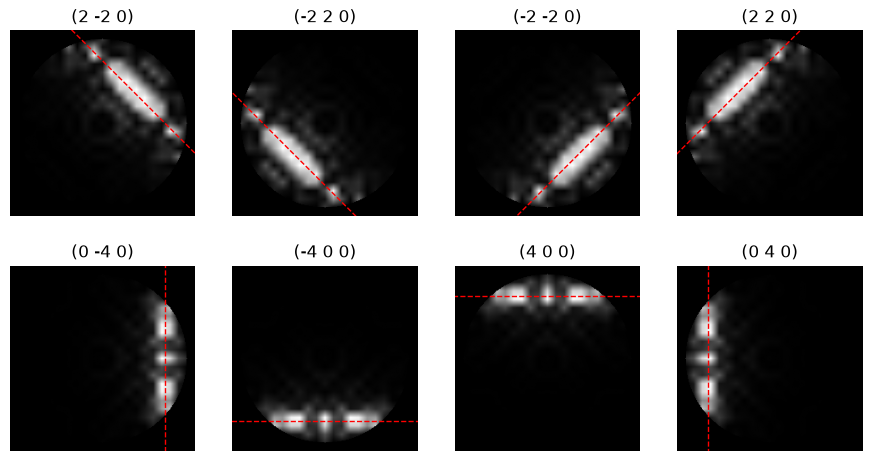

In [7]:
scale = lam * emc.cl * 1e3 / emc.pix_size          # pixels per 1/Å: λ L / p, L and p in µm
print(f'{scale:.1f} pixels per 1/Å; disk radius {0.5 * scale:.1f} pixels, measured {radius:.1f}')


def to_pixels(hkl):
    # (0 1 0) points right (+x) and (1 0 0) down (+y), in 1/Å times the scale
    return np.array([hkl[1], hkl[0]]) / a * scale


def bragg_line(ax, hkl, **style):
    g = to_pixels(hkl)
    u = g / np.linalg.norm(g)                  # along g
    v = np.array([-u[1], u[0]])                 # along the line
    foot = center - u * np.linalg.norm(g) / 2
    ends = np.array([foot - 1.2 * radius * v, foot + 1.2 * radius * v])
    ax.plot(ends[:, 0], ends[:, 1], **style)


fig, axes = plt.subplots(2, 4, figsize=(11, 5.6))
print()
print('  beam          band center, pixels from the disk center')
print('                predicted   measured')
for ax, i in zip(axes.flat, bright[1:]):
    hkl = beams[i]
    image = lacbed[i][1]
    ax.imshow(image, cmap='gray')
    bragg_line(ax, hkl, color='red', lw=1, ls='--')
    ax.set_title(label(hkl))
    zoom(ax)

    g = to_pixels(hkl)
    u = g / np.linalg.norm(g)
    r = np.arange(0, int(radius))
    x, y = np.rint(center - np.outer(r, u)).astype(int).T
    print(f'  {label(hkl):12s}   {np.linalg.norm(g) / 2:5.1f}       {r[image[y, x].argmax()]:3d}')
plt.show()

The bands lie on the predicted lines, within the few pixels of the bands' width and the
coarse sampling. The (4 0 0)-type lines are farther out than the (2 2 0)-type ones, since their
reflections are farther from the center.

The direct beam's image shows all the lines at once: wherever a reflection is at its Bragg
condition, it takes electrons from the direct beam.

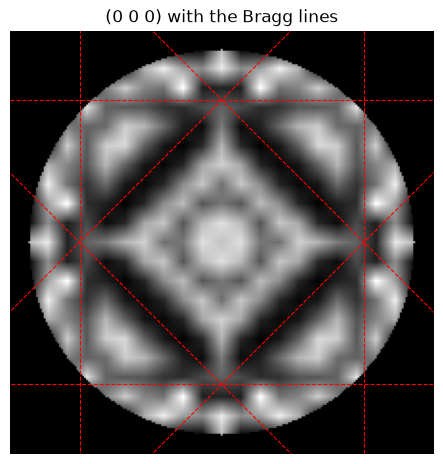

In [8]:
fig, ax = plt.subplots(figsize=(5.5, 5.5))
ax.imshow(image0, cmap='gray')
for i in bright[1:]:
    bragg_line(ax, beams[i], color='red', lw=0.8, ls='--')
ax.set_title('(0 0 0) with the Bragg lines')
zoom(ax)
plt.show()

Unlike in a two-beam picture, the lines don't simply darken the direct beam. Where lines
cross, several reflections are excited together, and the dynamic interactions between them
create the pattern of bands and spots. Spence and Zuo's chapter 6, *Large-Angle Methods*,
discusses how such patterns are used.

## Step 6: Sample thickness

`sample_thickness` sets a range of thicknesses, `(start, end, step)` in Å. LACBED gives one
image per thickness and beam, in that order: all beams at the first thickness, then all at the
next. Here is the direct beam at four thicknesses:

84 images: 4 thicknesses × 21 beams


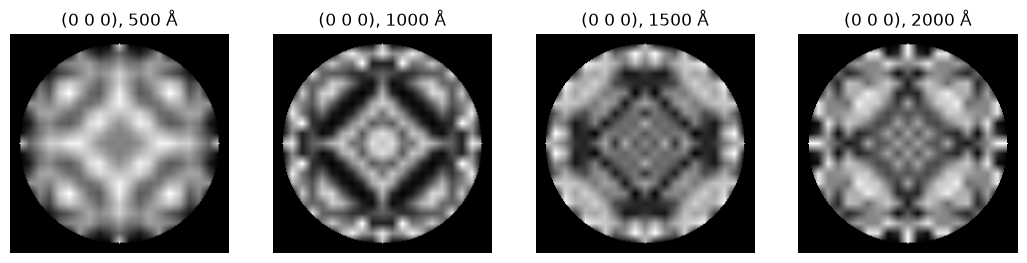

In [9]:
silicon.beginBloch(dbsize=0.5, sampling=10)
nbeams, beams = silicon.getCalculatedBeams()
series = silicon.getBlochImages(sample_thickness=(500, 2000, 500), nType=TY_LACBED)
silicon.endBloch()

print(len(series.blochList), 'images:', len(series.blochList) // nbeams, 'thicknesses ×', nbeams, 'beams')

fig, axes = plt.subplots(1, 4, figsize=(13, 3.6))
for k, ax in enumerate(axes):
    emc, image = series[k * nbeams]             # the (0 0 0) beam at each thickness
    ax.imshow(image, cmap='gray')
    ax.set_title(f'(0 0 0), {emc.simc.sth} Å')
    zoom(ax)
plt.show()

The thicker the sample, the more fringes the image has. Each Bloch wave's phase grows
with the thickness, and with it, how fast the interference between them changes with the
incident direction. These fringes are the thickness fringes of the dynamic diffraction notebook,
spread out over the incident directions; matching them to an experiment measures the sample's
thickness. At 2000 Å, the finest fringes come close to the spacing of the 10 sampling points,
and the image gets blocky; for thicker samples, raise `sampling`.

## Step 7: Another zone axis

At the [1 1 1] zone axis, Silicon's reflections in the zero layer form a hexagon. The camera
length is set to 200 mm, as above, so the disk fits the detector.

13 beams: (0 0 0), (2 0 -2), (2 -2 0), (0 2 -2), (0 -2 2), (-2 2 0), (-2 0 2), (4 -2 -2), (2 2 -4), (2 -4 2), (-2 4 -2), (-2 -2 4), (-4 2 2)


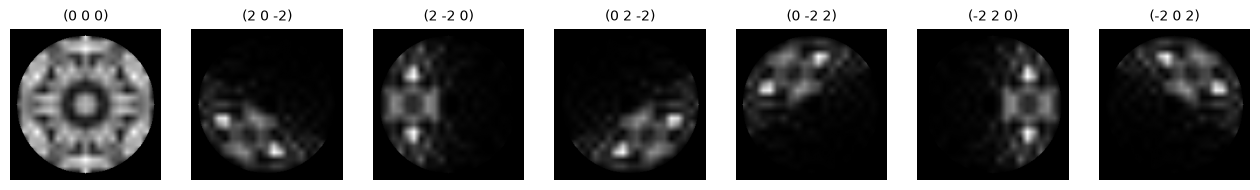

In [10]:
silicon.beginBloch(dbsize=0.5, sampling=10, em_controls=EMC(zone=(1, 1, 1), cl=200))
nbeams, beams = silicon.getCalculatedBeams()
zone111 = silicon.getBlochImages(sample_thickness=(1000, 1000, 100), nType=TY_LACBED)
silicon.endBloch()

print(nbeams, 'beams:', ', '.join(label(hkl) for hkl in beams))

fig, axes = plt.subplots(1, 7, figsize=(16, 2.9))
for ax, (emc, image), hkl in zip(axes, zone111.blochList, beams):
    ax.imshow(image, cmap='gray')
    ax.set_title(label(hkl), fontsize=10)
    zoom(ax)
plt.show()

The (0 0 0) image has six-fold symmetry. All 13 beams are in the zero-order Laue zone,
$h + k + l = 0$, so the calculation sees the crystal as if projected along [1 1 1], and the
projected diamond structure has a six-fold axis. Silicon's [1 1 1] axis itself is only
three-fold; in an experiment, the higher-order Laue zones show it. Reading the symmetry of CBED
and LACBED patterns like this is how electron diffraction determines point and space groups;
see Spence and Zuo's chapter 7, *Symmetry Determination*.

## Step 8: Save the images

`generateBloch` with `bSave=True` also saves all the images in one raw `.im3` file, in the
`bloch` folder of the pyEMAPS data folder: the folder named by the `PYEMAPS_DATA` environment
variable, or the current folder if it isn't set. [ImageJ](https://imagej.net/ij/) and
DigitalMicrograph can import it; see
[Third-party tools](https://emlab-solutions.github.io/pyemaps/user_guide/third_party.html).

In [11]:
from pyemaps.samples.si_lacbed import generate_lacbed_images

images = generate_lacbed_images(save=True)

The raw bloch image(s) of dimensions 512x512x21 and an offset of 8 bytes successfully saved to: 
C:\pyemaps_data\bloch\Silicon-20261114213255.im3
To view, import the file into ImageJ or other raw image visualization tools


The sample's `generate_lacbed_images` makes the images of Step 2 and, with `save=True`,
saves them: the file holds the 21 images one after the other, in the order of the calculated
beams.

## Try it yourself

1. **Disk size.** Simulate with `disk_size=0.3`. Which Bragg lines leave the disk?
2. **High voltage.** At 100 kV (`EMC(vt=100, cl=200)`), the wavelength is longer. Do the Bragg
   lines move on the detector? Does their position in 1/Å change?
3. **More beams.** `beginBloch(aperture=1.5, ...)` calculates the beams up to 1.5 1/Å. Which
   new reflections appear, and are any of them bright?
4. **Another crystal.** Simulate `Diamond`, which has Silicon's structure with a smaller cell.
   How do the Bragg lines change?

## Next

- The [dynamic diffraction notebook](si_bloch.ipynb): CBED patterns from the same Bloch wave
  calculation.
- The [scattering matrix notebook](si_scm.ipynb): inside the Bloch wave calculation at one
  incident direction.
- The references for [`generateBloch`](https://emlab-solutions.github.io/pyemaps/api/crystals.html#pyemaps.crystals.Crystal.generateBloch),
  [`beginBloch`](https://emlab-solutions.github.io/pyemaps/api/crystals.html#pyemaps.crystals.Crystal.beginBloch) and
  [`getBlochImages`](https://emlab-solutions.github.io/pyemaps/api/crystals.html#pyemaps.crystals.Crystal.getBlochImages).

## Further reading

J. C. H. Spence and J. M. Zuo, *Electron Microdiffraction* (Plenum, New York, 1992),
[doi:10.1007/978-1-4899-2353-0](https://doi.org/10.1007/978-1-4899-2353-0):

- chapter 2, *The Geometry of CBED Patterns*, for the Bragg lines in Step 5;
- chapter 6, *Large-Angle Methods*, for LACBED, the subject of this notebook;
- chapter 7, *Symmetry Determination*, for the symmetry in Step 7.

J. M. Zuo and J. C. H. Spence, *Advanced Transmission Electron Microscopy* (Springer, New York,
2017), [doi:10.1007/978-1-4939-6607-3](https://doi.org/10.1007/978-1-4939-6607-3):

- chapter 3, *The Geometry of Electron Diffraction Patterns*, for Step 5;
- chapter 5, *Dynamical Theory of Electron Diffraction for Perfect Crystals*, for Steps 5 and 6;
- chapter 11, *Crystal Symmetry*, for Step 7.